Original dataset shape: (4177, 9)

MISSING VALUE REMOVAL
---------------------
Missing values before: 0
Rows remaining: 4177
Missing values after: 0

OUTLIER SUMMARY
---------------


,Feature,Lower Bound,Upper Bound,Outlier Count
0,Length,0.2025,0.8625,49
1,Diameter,0.1550,0.6750,59
2,Height,0.0400,0.2400,29
3,Whole weight,-0.6258,2.2202,30
4,Shucked weight,-0.2880,0.9760,48
5,Viscera weight,-0.1458,0.4922,26
6,Shell weight,-0.1685,0.6275,35



OUTLIER REMOVAL RESULTS
-----------------------
Rows removed: 153
Rows remaining: 4024

PCA INPUT FEATURES
------------------
['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Sex_I', 'Sex_M']
PCA input shape: (4024, 9)

Standardized feature means (approximately zero):


Length           -0.0
Diameter          0.0
Height           -0.0
Whole weight     -0.0
Shucked weight    0.0
Viscera weight    0.0
Shell weight      0.0
Sex_I             0.0
Sex_M             0.0
dtype: float64


Standardized feature standard deviations (approximately one):


Length            1.0
Diameter          1.0
Height            1.0
Whole weight      1.0
Shucked weight    1.0
Viscera weight    1.0
Shell weight      1.0
Sex_I             1.0
Sex_M             1.0
dtype: float64

... (3 outputs left out)

,Principal Component,Eigenvalue,Explained Variance (%),Cumulative Variance (%)
0,PC1,6.9478,77.1791,77.1791
1,PC2,1.1563,12.8450,90.0241
2,PC3,0.4008,4.4526,94.4767
3,PC4,0.1875,2.0831,96.5598
4,PC5,0.1323,1.4693,98.0290



COMPONENT LOADINGS
------------------


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
Length,0.3663,-0.1020,0.0680,0.1176,0.5754,0.0086,0.1322,-0.6987,0.0130
Diameter,0.3669,-0.0925,0.0428,0.1744,0.5537,0.0788,0.0781,0.7111,-0.0003
Height,0.3520,-0.0751,-0.0248,0.7052,-0.3695,-0.4791,-0.0797,-0.0134,0.0001
Whole weight,0.3728,-0.0897,0.0708,-0.2469,-0.1917,0.0916,-0.1374,0.0069,0.8503
Shucked weight,0.3599,-0.0911,0.1340,-0.5133,0.0043,-0.3990,-0.5332,0.0195,-0.3700
Viscera weight,0.3634,-0.0856,0.0381,-0.3215,-0.3083,-0.0883,0.7820,0.0418,-0.1988
Shell weight,0.3633,-0.0888,0.0288,0.1451,-0.3037,0.7673,-0.2308,-0.0596,-0.3169
Sex_I,-0.2453,-0.5248,0.8087,0.0839,-0.0400,0.0079,0.0373,0.0152,0.0052
Sex_M,0.1206,0.8175,0.5600,0.0508,-0.0110,0.0108,0.0242,0.0026,0.0018



PC1: TOP FIVE FEATURE LOADINGS
---------------------------------------------
Whole weight: 0.3728
Diameter: 0.3669
Length: 0.3663
Viscera weight: 0.3634
Shell weight: 0.3633

PC2: TOP FIVE FEATURE LOADINGS
---------------------------------------------
Sex_M: 0.8175
Sex_I: -0.5248
Length: -0.1020
Diameter: -0.0925
Shucked weight: -0.0911

PC3: TOP FIVE FEATURE LOADINGS
---------------------------------------------
Sex_I: 0.8087
Sex_M: 0.5600
Shucked weight: 0.1340
Whole weight: 0.0708
Length: 0.0680

PC4: TOP FIVE FEATURE LOADINGS
---------------------------------------------
Height: 0.7052
Shucked weight: -0.5133
Viscera weight: -0.3215
Whole weight: -0.2469
Diameter: 0.1744

PC5: TOP FIVE FEATURE LOADINGS
---------------------------------------------
Length: 0.5754
Diameter: 0.5537
Height: -0.3695
Viscera weight: -0.3083
Shell weight: -0.3037


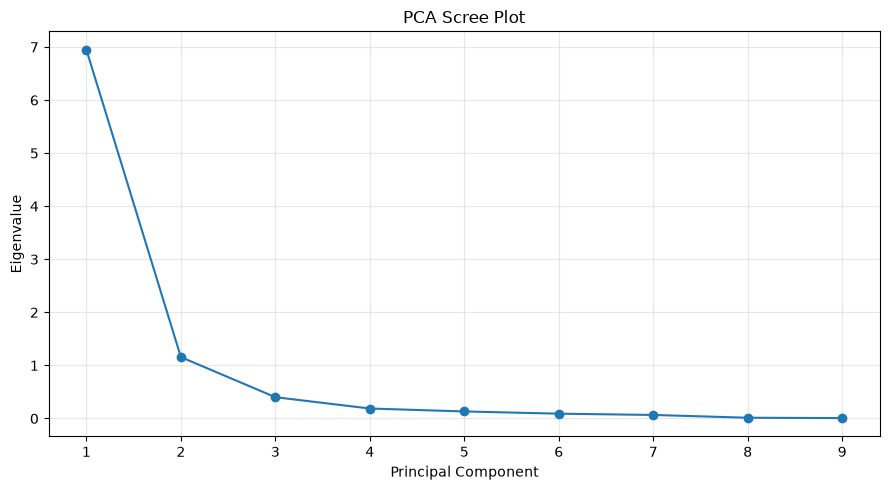

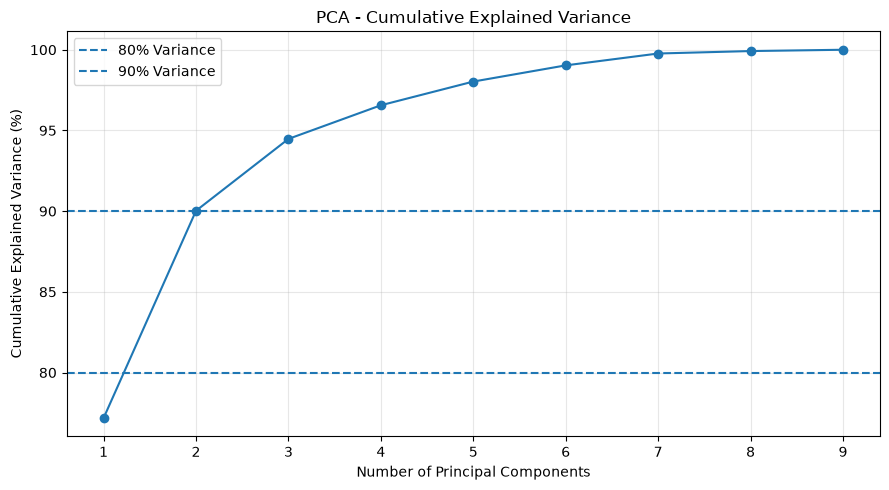


PCA results saved successfully.


In [1]:
# Imports and Configuration

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

FEATURE_NAMES = [
    "Sex", "Length", "Diameter", "Height", "Whole weight",
    "Shucked weight", "Viscera weight", "Shell weight", "Rings"
]

NUMERIC_FEATURES = [
    "Length", "Diameter", "Height", "Whole weight",
    "Shucked weight", "Viscera weight", "Shell weight"
]

# Load the original data

df = pd.read_csv(
    "abalone.data",
    header=None,
    names=FEATURE_NAMES,
    skipinitialspace=True
)

# Convert numeric columns
for col in NUMERIC_FEATURES + ["Rings"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Original dataset shape:", df.shape)

# Remove missing values

missing_before = df.isna().sum().sum()

df_clean = df.dropna().copy()

missing_after = df_clean.isna().sum().sum()

print("\nMISSING VALUE REMOVAL")
print("---------------------")
print("Missing values before:", missing_before)
print("Rows remaining:", len(df_clean))
print("Missing values after:", missing_after)

# Remove IQR outliers

# Calculate IQR fences for each physical measurement.
# A row is removed if ANY measurement is outside its fences.

outlier_mask = pd.Series(False, index=df_clean.index)

outlier_summary = []

for col in NUMERIC_FEATURES:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    col_outliers = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    )

    outlier_mask |= col_outliers

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(col_outliers.sum())
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

print("\nOUTLIER SUMMARY")
print("---------------")
display(outlier_summary_df.round(4))

rows_before_outlier_removal = len(df_clean)

df_clean = df_clean.loc[~outlier_mask].copy()

rows_removed = rows_before_outlier_removal - len(df_clean)

print("\nOUTLIER REMOVAL RESULTS")
print("-----------------------")
print("Rows removed:", rows_removed)
print("Rows remaining:", len(df_clean))

# Preprocess features for PCA

# Exclude Rings because it is the prediction target.
X_numeric = df_clean[NUMERIC_FEATURES].copy()

# One-hot encode Sex.
X_sex = pd.get_dummies(
    df_clean["Sex"],
    prefix="Sex",
    drop_first=True,
    dtype=int
)

# Combine numeric and encoded categorical features.
X = pd.concat([X_numeric, X_sex], axis=1)

print("\nPCA INPUT FEATURES")
print("------------------")
print(list(X.columns))
print("PCA input shape:", X.shape)

# Standardize features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier inspection.
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

print("\nStandardized feature means (approximately zero):")
display(X_scaled_df.mean().round(4))

print("\nStandardized feature standard deviations (approximately one):")
display(X_scaled_df.std(ddof=0).round(4))

# Perform PCA

pca = PCA()

principal_components = pca.fit_transform(X_scaled)

# Create component names.
component_names = [
    f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))
]

# Explained variance results.
pca_results = pd.DataFrame({
    "Principal Component": component_names,
    "Eigenvalue": pca.explained_variance_,
    "Explained Variance (%)":
        pca.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)":
        np.cumsum(pca.explained_variance_ratio_) * 100
})

print("\nALL PRINCIPAL COMPONENTS")
print("------------------------")
display(pca_results.round(4))

# Top five components

top_5_components = pca_results.head(5).copy()

print("\nTOP FIVE PRINCIPAL COMPONENTS")
print("-----------------------------")
display(top_5_components.round(4))

# Feature loadings

loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=component_names
)

print("\nCOMPONENT LOADINGS")
print("------------------")
display(loadings.round(4))

# Top five features of the top components

for component in component_names[:5]:

    component_loadings = loadings[component]

    top_features = (
        component_loadings
        .abs()
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"\n{component}: TOP FIVE FEATURE LOADINGS")
    print("-" * 45)

    for feature in top_features.index:
        value = component_loadings[feature]

        print(f"{feature}: {value:.4f}")


# Scree Plot

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(pca_results) + 1),
    pca.explained_variance_,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(pca_results) + 1))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Cumulative Explained Variance

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(pca_results) + 1),
    np.cumsum(pca.explained_variance_ratio_) * 100,
    marker="o"
)

plt.axhline(
    y=80,
    linestyle="--",
    label="80% Variance"
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% Variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Cumulative Explained Variance")

plt.xticks(range(1, len(pca_results) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Save Results

pca_results.to_csv("pca_component_results.csv", index=False)
loadings.to_csv("pca_feature_loadings.csv")

print("\nPCA results saved successfully.")
